# Archive of Results_paper.ipynb

Cells moved out of the working notebook because they make exhibits that are not in the final paper (AFG_paper_revised.docx), or are exploratory. They are kept as they were and are not maintained; they may depend on variables defined in the original notebook.

## Moved from `Results_paper.ipynb`: cells 269cce9e, 2f68065b, faa44373, 4c498298, 54ffc942, c1d6145d, 9998f04b, 7aab5e7b, 0cedd899, c26b3902, 5b624647, e3eeb7c9, 05bc349d, fd1b1e89, 8e245f80, 792dd92d

In [ ]:
'''
Cumulative distribution of nighttime light emissions across markets
'''
import seaborn as sns
from matplotlib.ticker import PercentFormatter, MultipleLocator

# x axis: log(1 + light). Unlit markets (light == 0) sit at x = 0, so the height of the
# curve at zero is the unlit share, the same definition as the positive-emissions bars.
X_LABEL = "Median nighttime light emissions, log(1 + radiance)"


def draw_cdf(year, out_path):
        col = "light_%d" % year

        kabul_x = np.log1p(KABUL_REF[year])

        fig, ax = plt.subplots(figsize=(6.5, 4.5))

        # Okabe-Ito green for the combined OSM series.
        GREEN = "#009E73"
        series = [("Periodic markets", ["Periodic"], ORANGE)]
        for k, (lab, grps, color) in enumerate(series):
            vals = ntl[ntl['group'].isin(grps)][col].copy(deep=True)
            n = len(vals)
            vals = np.sort(vals.fillna(0).values)
            cum_share = np.arange(1, len(vals) + 1) / len(vals)

            unlit_share = (vals <= 0).mean()      # same as the positive-emissions bars

            x = np.log1p(vals)
            # Vertical riser at x=0 carrying the curve down to the x-axis.
            ax.plot(np.concatenate([[0.0], x]),
                    np.concatenate([[0.0], cum_share]),
                    color=color, linewidth=2.2, solid_capstyle="round",
                    label="%s (n=%d)" % (lab, n))

            # Note next to the top of the riser at x=0.
            ax.annotate("%.0f%% of markets\nhave no light emissions" % (100 * unlit_share),
                        xy=(0, unlit_share),
                        xytext=(0.4, min(unlit_share, 0.2)),
                        color=color, fontsize=9, ha="left", va="center",
                        linespacing=1.3)

        # Kabul reference marker.
        ax.axvline(kabul_x, color="0.55", linestyle=(0, (4, 3)), linewidth=1)
        ax.text(kabul_x - 0.2, 0.30, "Median Kabul\ncity center",
                color="0.4", fontsize=9, va="center", ha="right", linespacing=1.3)

        ax.set_xlim(-0.35, np.ceil(kabul_x))
        ax.set_ylim(0, 1.0)
        ax.set_xlabel(X_LABEL)
        ax.set_ylabel("Cumulative share of markets")

        ax.yaxis.set_major_formatter(PercentFormatter(xmax=1.0, decimals=0))
        ax.yaxis.set_major_locator(MultipleLocator(0.2))
        ax.xaxis.set_major_locator(MultipleLocator(2))
        ax.grid(axis="y", color="0.9", linewidth=0.8)
        ax.set_axisbelow(True)

        ax.legend(loc="lower right", frameon=False, fontsize=10)
        sns.despine()
        fig.tight_layout()
        fig.savefig(out_path, dpi=200, bbox_inches="tight")
        print("saved", os.path.basename(out_path))
        plt.show()


for y in FIG_YEARS:
    draw_cdf(y, os.path.join(OUT_FIG, "cdf_nighttime_light_%d_periodic_vs_osm.png" % y))


In [ ]:
'''
Cumulative distribution of nighttime light emissions across markets
(one panel per year, single figure)
'''
import seaborn as sns
from matplotlib.ticker import PercentFormatter, MultipleLocator

GREEN = "#009E73"  # Okabe-Ito green for the combined OSM series
series = [("Periodic markets", ["Periodic"], ORANGE),
          ("All OSM markets", ["OSM only", "OSM overlap"], GREEN)]
# Or use only periodic markets: series = [("Periodic markets", ["Periodic"], ORANGE)]

def draw_cdf_panel(ax, year, show_ylabel=True):
    col = "light_%d" % year
    kabul_x = np.log1p(KABUL_REF[year])

    for lab, grps, color in series:
        vals = ntl[ntl["group"].isin(grps)][col].copy(deep=True)
        n = len(vals)
        vals = np.sort(vals.fillna(0).values)
        cum_share = np.arange(1, n + 1) / n
        x = np.log1p(vals)      # unlit markets (light == 0) at x = 0
        # Vertical riser at x=0 carrying the curve down to the x-axis.
        ax.plot(np.concatenate([[0.0], x]),
                np.concatenate([[0.0], cum_share]),
                color=color, linewidth=2.2, solid_capstyle="round",
                label="%s (n=%d; %.0f%% unlit)" % (lab, n, 100 * (vals <= 0).mean()))

    # Kabul reference marker.
    ax.axvline(kabul_x, color="0.55", linestyle=(0, (4, 3)), linewidth=1)
    ax.text(kabul_x - 0.2, 0.30, "Median Kabul\ncity center",
            color="0.4", fontsize=9, va="center", ha="right", linespacing=1.3)

    ax.set_title(str(year), fontsize=12, fontweight="semibold")
    ax.set_xlim(-0.35, np.ceil(kabul_x))
    ax.set_ylim(0, 1.0)
    ax.set_xlabel(X_LABEL)
    if show_ylabel:
        ax.set_ylabel("Cumulative share of markets")
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1.0, decimals=0))
    ax.yaxis.set_major_locator(MultipleLocator(0.2))
    ax.xaxis.set_major_locator(MultipleLocator(2))
    ax.grid(axis="y", color="0.9", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.legend(loc="lower right", frameon=False, fontsize=10)


fig, axes = plt.subplots(1, len(FIG_YEARS), figsize=(6.5 * len(FIG_YEARS), 4.5),
                         sharey=True)
axes = np.atleast_1d(axes)

for i, (ax, y) in enumerate(zip(axes, FIG_YEARS)):
    draw_cdf_panel(ax, y, show_ylabel=(i == 0))

sns.despine()
fig.tight_layout()
out_path = os.path.join(OUT_FIG, "cdf_nighttime_light_%s_periodic_vs_osm.png"
                        % "_".join(map(str, FIG_YEARS)))
fig.savefig(out_path, dpi=200, bbox_inches="tight")
print("saved", os.path.basename(out_path))
plt.show()


saved positive_emissions_share_by_access_2018.png


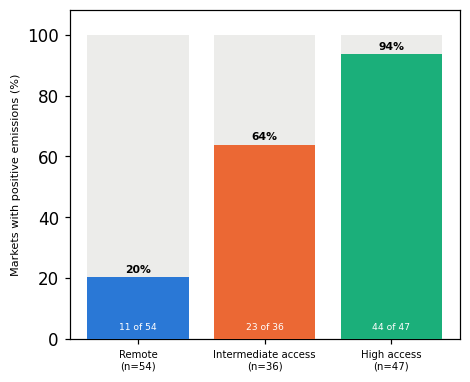

saved emissions_by_access_2018.png


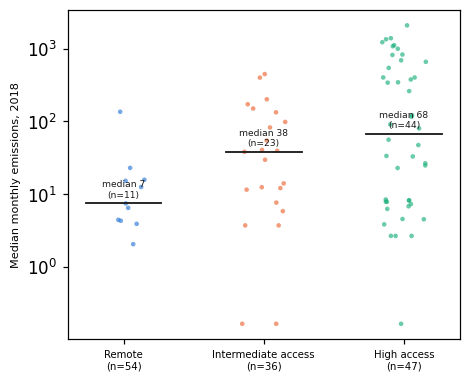

saved positive_emissions_share_by_access_2025.png


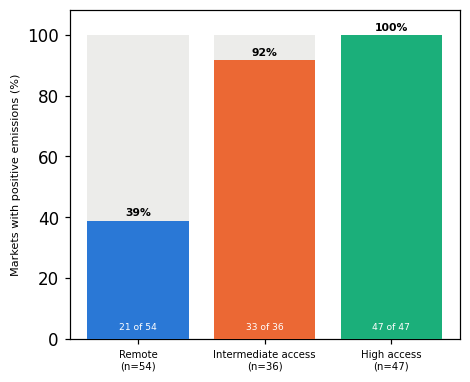

saved emissions_by_access_2025.png


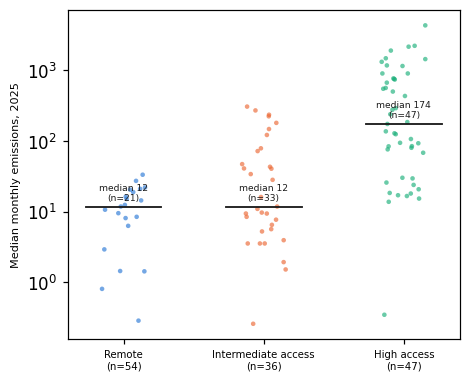

In [21]:
# Light intensity by access category, as independent figures per year.
# Access category comes from mkt_access.csv (its `density` field) and is defined
# for the 137 periodic markets only; they join to `ntl` on orig_id == mktID.
# Emissions use the median monthly BNR buffer total from Section 2 (light_<year>).

MKT_ACCESS = os.path.join(BASE, "document", "Repo_09042026", "data", "derived", "mkt_access.csv")
DENS = {"low density": "Remote", "mid density": "Intermediate access", "high density": "High access"}
ACC_ORD = ["Remote", "Intermediate access", "High access"]
ACC_COL = {"Remote": "#2a78d6", "Intermediate access": "#eb6834", "High access": "#1baf7a"}

acc = pd.read_csv(MKT_ACCESS)
acc["access"] = acc.density.map(DENS)
per = ntl[ntl.group == "Periodic"].merge(acc[["mktID", "access"]],
                                         left_on="orig_id", right_on="mktID", how="left")
assert per.access.notna().all(), \
    "missing access category for %s" % per.loc[per.access.isna(), "orig_id"].tolist()


def draw_positive_share(year, out_path):
    """Share of markets with any positive emissions, by access category."""
    col = "light_%d" % year
    sh = per.groupby("access")[col].apply(lambda s: 100 * (s > 0).mean()).reindex(ACC_ORD)
    nn = per.groupby("access").size().reindex(ACC_ORD)

    fig, ax = plt.subplots(figsize=(4.2, 3.4))
    ax.bar(range(len(ACC_ORD)), 100, color="#ececea", zorder=2)
    ax.bar(range(len(ACC_ORD)), sh.values, color=[ACC_COL[k] for k in ACC_ORD], zorder=3)
    for i, (v, k) in enumerate(zip(sh.values, ACC_ORD)):
        ax.annotate(f"{v:.0f}%", (i, v), ha="center", fontsize=7, fontweight="bold",
                    xytext=(0, 3), textcoords="offset points")
        ax.annotate(f"{int(round(v * nn[k] / 100))} of {nn[k]}", (i, 3), ha="center",
                    fontsize=6, color="white")
    ax.set_xticks(range(len(ACC_ORD)))
    ax.set_xticklabels([f"{k}\n(n={nn[k]})" for k in ACC_ORD], fontsize=6.6)
    ax.set_ylabel("Markets with positive emissions (%)", fontsize=7.4); ax.set_ylim(0, 108)
    # ax.set_title(f"Share of markets with positive emissions ({year})",
                #  fontsize=7.4, loc="left", pad=4)
    fig.tight_layout(pad=0.4)
    fig.savefig(out_path, dpi=200, bbox_inches="tight")
    print("saved", os.path.basename(out_path))
    plt.show()


def draw_emissions(year, out_path):
    """Emissions of the lit markets, by access category; median over lit markets only."""
    col = "light_%d" % year
    nn = per.groupby("access").size().reindex(ACC_ORD)

    fig, ax = plt.subplots(figsize=(4.2, 3.4))
    rng = np.random.RandomState(0)
    for i, k in enumerate(ACC_ORD):
        s = per.loc[per.access == k, col]
        s = s[s > 0]
        ax.scatter(i + rng.uniform(-.16, .16, len(s)), s, s=9, color=ACC_COL[k],
                   alpha=.65, edgecolor="none", zorder=3)
        med = s.median()
        ax.plot([i - .27, i + .27], [max(med, .3)] * 2, color="#1a1a1a", lw=1.2, zorder=4)
        ax.annotate(f"median {med:,.0f}\n(n={len(s)})", (i, max(med, .3)), fontsize=6,
                    color="#1a1a1a", ha="center", xytext=(0, 4), textcoords="offset points")
    ax.set_yscale("symlog", linthresh=1)
    ax.set_xticks(range(len(ACC_ORD)))
    ax.set_xticklabels([f"{k}\n(n={nn[k]})" for k in ACC_ORD], fontsize=6.6)
    ax.set_ylabel(f"Median monthly emissions, {year}", fontsize=7.4)
    # ax.set_title(f"Emissions in {year}, by access category", fontsize=7.4, loc="left", pad=4)
    fig.tight_layout(pad=0.4)
    fig.savefig(out_path, dpi=200, bbox_inches="tight")
    print("saved", os.path.basename(out_path))
    plt.show()

for y in FIG_YEARS:
    draw_positive_share(y, os.path.join(OUT_FIG, "positive_emissions_share_by_access_%d.png" % y))
    draw_emissions(y, os.path.join(OUT_FIG, "emissions_by_access_%d.png" % y))


In [ ]:
"""
Cumulative distribution of nighttime light emissions: all periodic markets and by access category
"""
# Same construction as draw_cdf above (median monthly BNR buffer total on a log(1 + x) axis, unlit
# markets at x = 0), for the 137 periodic markets in `per`. The access lines use the access-category
# colours of the figures above, and differ in line style too, so they can be told apart without
# colour. Each line's unlit share (light == 0, as in the bar charts) goes in the legend.
CDF_SERIES = [("All periodic markets", None,                  "#1a1a1a",                        "-",  2.6),
              ("High access",          "High access",         ACC_COL["High access"],           "-",  1.8),
              ("Intermediate access",  "Intermediate access", ACC_COL["Intermediate access"],   "--", 1.8),
              ("Remote",               "Remote",              ACC_COL["Remote"],                ":",  2.2)]


def draw_cdf_by_access(year, out_path):
    col = "light_%d" % year
    kabul_x = np.log1p(KABUL_REF[year])

    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    for lab, grp, color, ls, lw in CDF_SERIES:
        vals = per[col] if grp is None else per.loc[per.access == grp, col]
        n = len(vals)
        vals = np.sort(vals.fillna(0).values)
        cum_share = np.arange(1, n + 1) / n
        unlit = 100 * (vals <= 0).mean()
        x = np.log1p(vals)
        # Vertical riser at x=0 carrying the curve down to the x-axis.
        ax.plot(np.concatenate([[0.0], x]), np.concatenate([[0.0], cum_share]),
                color=color, linestyle=ls, linewidth=lw, solid_capstyle="round",
                label="%s (n=%d; %.0f%% unlit)" % (lab, n, unlit))

    # Kabul reference marker.
    ax.axvline(kabul_x, color="0.55", linestyle=(0, (4, 3)), linewidth=1)
    ax.text(kabul_x - 0.2, 0.30, "Median Kabul\ncity center",
            color="0.4", fontsize=9, va="center", ha="right", linespacing=1.3)

    ax.set_xlim(-0.35, np.ceil(kabul_x))
    ax.set_ylim(0, 1.0)
    ax.set_xlabel(X_LABEL)
    ax.set_ylabel("Cumulative share of markets")
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1.0, decimals=0))
    ax.yaxis.set_major_locator(MultipleLocator(0.2))
    ax.xaxis.set_major_locator(MultipleLocator(2))
    ax.grid(axis="y", color="0.9", linewidth=0.8)
    ax.set_axisbelow(True)

    ax.legend(loc="lower right", bbox_to_anchor=(0.92, 0.0), frameon=False, fontsize=11)   # clear of the Kabul line
    sns.despine()
    fig.tight_layout()
    fig.savefig(out_path, dpi=200, bbox_inches="tight")
    print("saved", os.path.basename(out_path))
    plt.show()


for y in FIG_YEARS:
    draw_cdf_by_access(y, os.path.join(OUT_FIG, "cdf_nighttime_light_%d_by_access.png" % y))

In [ ]:
'''
All periodic markets: light values (left) and CDF (right), 2018 and 2025, in one figure
'''
years = [2018, 2025]
colors = [BLUE, ORANGE]
values = [per[f"light_{year}"].fillna(0).to_numpy() for year in years]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.6))

# Left: market values by year
rng = np.random.RandomState(0)
for i, (year, vals, color) in enumerate(zip(years, values, colors)):
    jitter = rng.uniform(-0.12, 0.12, size=len(vals))
    ax1.scatter(i + jitter, vals, s=18, alpha=0.65, color=color,
                edgecolor="none", zorder=3)

    median = np.median(vals)
    ax1.plot([i - 0.22, i + 0.22], [median, median],
             color="#222222", linewidth=2, zorder=4)
    ax1.annotate(f"Median: {median:,.1f}\nn={len(vals)}",
                 (i, median), xytext=(0, 7), textcoords="offset points",
                 ha="center", fontsize=8)

ax1.set_xticks(range(len(years)))
ax1.set_xticklabels([str(year) for year in years])
ax1.set_ylabel("Median monthly BNR buffer total")
ax1.set_title("A. Nighttime light values across periodic markets", fontsize=11, loc="left")
ax1.set_yscale("symlog", linthresh=1)
ax1.grid(axis="y", color="0.9", linewidth=0.8)
ax1.set_axisbelow(True)


def draw_periodic_cdf(ax):
    """CDF of all periodic markets, one line per year, on a log(1 + x) axis. Unlit
    (light == 0) is the same definition as the positive-emissions bar chart."""
    max_x = max(max(np.log1p(float(v.max())) for v in values),
                *(np.log1p(KABUL_REF[year]) for year in years))
    x_right = max(2, 2 * np.ceil(max_x / 2))
    for year, vals, color in zip(years, values, colors):
        vals = np.sort(vals)
        n = len(vals)
        unlit = 100 * (vals <= 0).mean()
        ax.plot(np.r_[0.0, np.log1p(vals)], np.r_[0.0, np.arange(1, n + 1) / n],
                color=color, linewidth=2.2, solid_capstyle="round",
                label="%d (n=%d; %.0f%% unlit)" % (year, n, unlit))
        ax.axvline(np.log1p(KABUL_REF[year]), color=color, linestyle=(0, (4, 3)),
                   linewidth=1, alpha=0.8)
    ax.text(np.log1p(KABUL_REF[years[0]]) - 0.2, 0.30, "Median Kabul\ncity center",
            color="0.4", fontsize=9, va="center", ha="right", linespacing=1.3)
    ax.set_xlim(-0.35, x_right)
    ax.set_ylim(0, 1)
    ax.set_xlabel(X_LABEL)
    ax.set_ylabel("Cumulative share of markets")
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1.0, decimals=0))
    ax.yaxis.set_major_locator(MultipleLocator(0.2))
    ax.xaxis.set_major_locator(MultipleLocator(2))
    ax.grid(axis="y", color="0.9", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.legend(loc="lower right", bbox_to_anchor=(0.92, 0.0), frameon=False, fontsize=10)


# Right: CDF of all periodic markets, one line per year
draw_periodic_cdf(ax2)
ax2.set_title("B. Cumulative distribution", fontsize=11, loc="left")

sns.despine()
fig.tight_layout()

all_periodic_out = os.path.join(
    OUT_FIG, "periodic_market_light_values_cdf_2018_2025.png"
)
fig.savefig(all_periodic_out, dpi=300, bbox_inches="tight")
print("saved", os.path.basename(all_periodic_out))
plt.show()

# The CDF on its own (Figure 5, panel c).
fig, ax = plt.subplots(figsize=(5.8, 4.6))
draw_periodic_cdf(ax)
sns.despine()
fig.tight_layout()
cdf_out = os.path.join(OUT_FIG, "periodic_market_light_cdf_2018_2025.png")
fig.savefig(cdf_out, dpi=300, bbox_inches="tight")
print("saved", os.path.basename(cdf_out))
plt.show()


## 5. Event study

Year dummies (2020 omitted) interacted with three time-invariant baseline
market characteristics: once-a-week trading, distance to the nearest OSM
market, and log catchment population. Market and year fixed effects; standard
errors clustered by district. Time-varying controls: log district deaths per
100,000 and growing-season NDVI deviation.

| Model | Sample | Outcome |
|---|---|---|
| A | all 137 markets | market activity index, 2020 = 100 |
| A | always-lit markets | market activity index, 2020 = 100 |
| B | ever-lit markets | log Feb-Jun median BNR radiance |

In [24]:
# The event-study panel now names these columns differently (see the legacy branch of
# stata/run_event_study_ACCESS.do): log_pop is ln_pop_30mixed, and the log Feb-Jun
# median BNR radiance is log_light_emissions.
panel = panel.assign(log_pop=panel.ln_pop_30mixed, log_feb_jun_bnr=panel.log_light_emissions)

NONBASE_YEARS = [y for y in YEARS if y != 2020]
CHARS = {"once_a_week_c": "once_a_week", "dist_osm_c": "dist_osm", "log_pop_c": "log_pop"}
PRE, POST = [2018, 2019], [2021, 2022, 2023, 2024, 2025]
REQ = ["once_a_week_c", "dist_osm_c", "log_pop_c", "log_deaths_pc", "ndvi_dev"]
YRS_ORDER = YEARS


def _clus(formula, data, group):
    """OLS with cluster-robust SEs and p-values from t(G-1)."""
    g = data[group]
    f = smf.ols(formula, data=data).fit(cov_type="cluster", cov_kwds={"groups": g}, use_t=True)
    G = g.nunique()
    f._p = {k: 2 * (1 - _st.t.cdf(abs(f.params[k] / f.bse[k]), G - 1)) for k in f.params.index}
    return f


def add_centered(df, market_cols=("once_a_week", "dist_osm", "log_pop")):
    d = df.copy()
    means = d.drop_duplicates("mktID")[list(market_cols)].mean()
    for c in market_cols:
        d[c + "_c"] = d[c] - means[c]
    for cvar in CHARS:
        for y in NONBASE_YEARS:
            d["%s_%d" % (cvar, y)] = d[cvar] * (d.year == y)
    return d, means


def _formula(outcome):
    inter = " + ".join("%s_%d" % (cvar, y) for cvar in CHARS for y in NONBASE_YEARS)
    return ("%s ~ C(mktID) + C(year, Treatment(2020)) + %s + log_deaths_pc + ndvi_dev"
            % (outcome, inter))


def run_model(df, outcome, label, dropcols):
    d, _ = add_centered(df)
    d = d.dropna(subset=dropcols)
    f = _clus(_formula(outcome), d, "Pcode_24")
    print("=== %s ===  n=%d  markets=%d  clusters=%d  R2=%.4f"
          % (label, int(f.nobs), d.mktID.nunique(), d.Pcode_24.nunique(), f.rsquared))
    return f, d


def joint_test(f, cvar, years):
    terms = ["%s_%d" % (cvar, y) for y in years if "%s_%d" % (cvar, y) in f.params.index]
    if not terms:
        return np.nan
    return float(f.wald_test(" , ".join("%s = 0" % t for t in terms), use_f=True).pvalue)

In [25]:
lit_markets = sorted(panel.loc[panel.lit_market == 1, "mktID"].unique())
ever_lit_markets = sorted(panel.loc[panel.ever_lit_market == 1, "mktID"].unique())
lit_panel = panel[panel.mktID.isin(lit_markets)].copy()
ever_panel = panel[panel.mktID.isin(ever_lit_markets)].copy()
print("always-lit markets: %d    ever-lit markets: %d\n" % (len(lit_markets), len(ever_lit_markets)))

fA_all, dA_all = run_model(panel, "y_activity",
                           "Model A - all markets", REQ + ["y_activity"])
fA_lit, dA_lit = run_model(lit_panel, "y_activity",
                           "Model A - always-lit markets (n=%d)" % len(lit_markets),
                           REQ + ["y_activity"])
fB_ever, dB_ever = run_model(ever_panel, "log_feb_jun_bnr",
                             "Model B - ever-lit markets (n=%d)" % len(ever_lit_markets),
                             REQ + ["log_feb_jun_bnr"])

always-lit markets: 52    ever-lit markets: 107

=== Model A - all markets ===  n=1084  markets=137  clusters=71  R2=0.4835
=== Model A - always-lit markets (n=52) ===  n=416  markets=52  clusters=35  R2=0.5579
=== Model B - ever-lit markets (n=107) ===  n=606  markets=107  clusters=63  R2=0.8997


### Event-study coefficient figure

saved C:\Users\wb434633\WBG\Christina Wieser - Afghanistan\Geospatial information\MarketActivityIndex\output_paper\event_study\event_study_everlit_figure.png


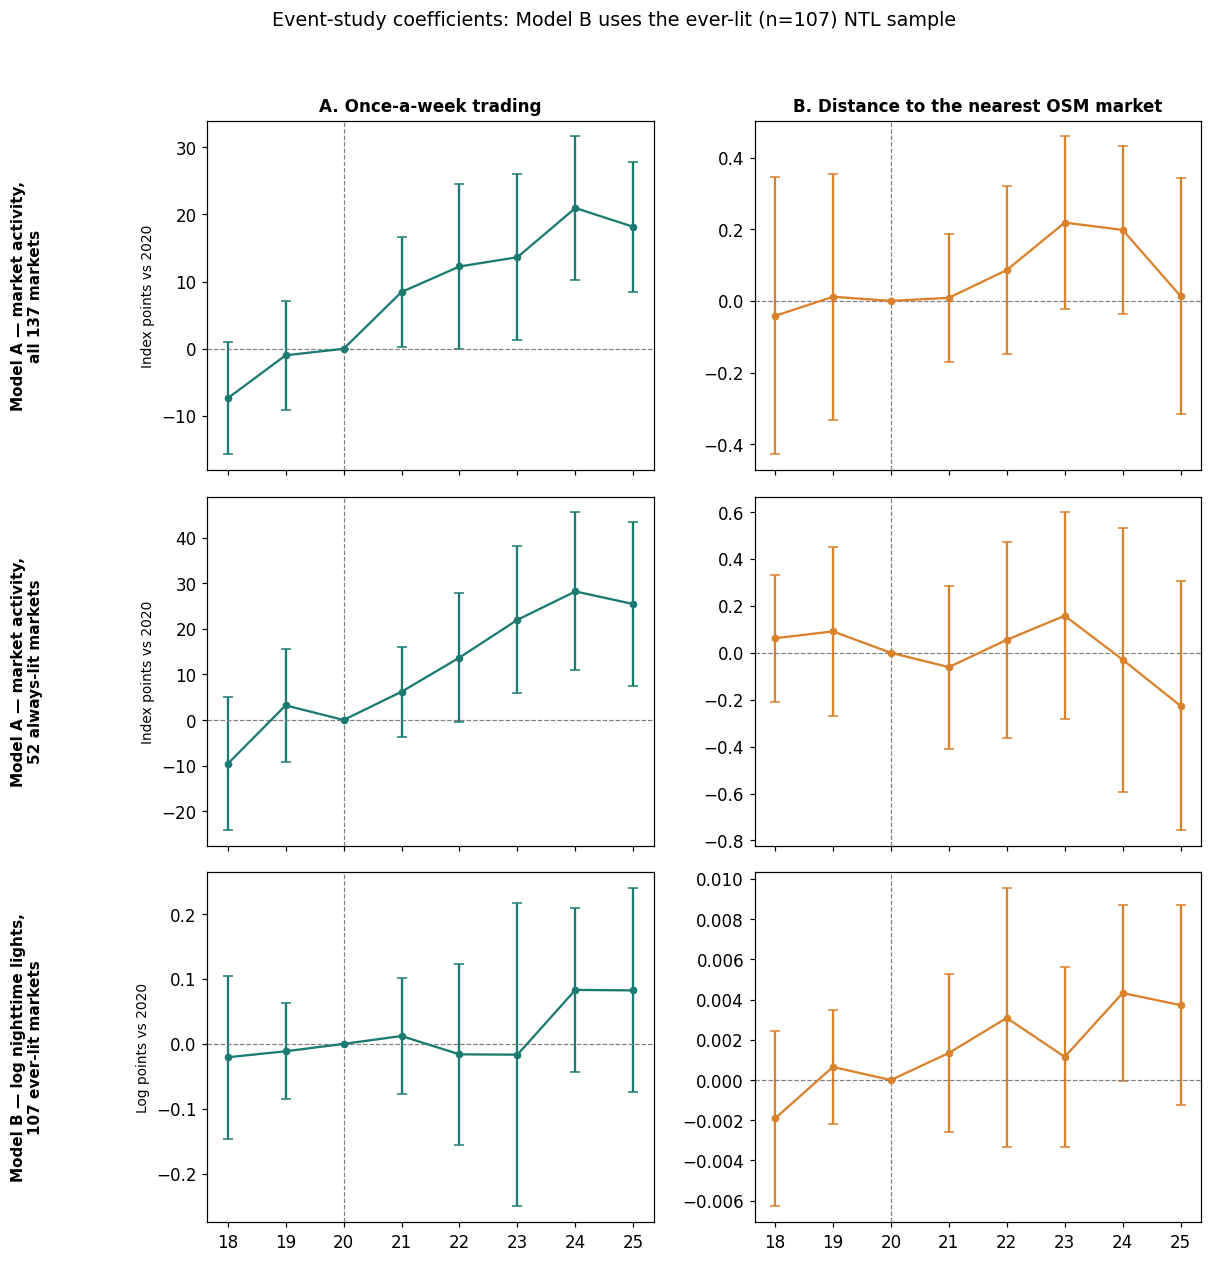

In [26]:
def new_series(f, cvar):
    return {y: (f.params["%s_%d" % (cvar, y)], f.bse["%s_%d" % (cvar, y)])
            for y in NONBASE_YEARS}


def to_xy(series):
    x, y, lo, hi = [], [], [], []
    for yr in YEARS:
        if yr == 2020:
            x.append(yr); y.append(0.0); lo.append(0.0); hi.append(0.0)
        else:
            c, se = series[yr]
            x.append(yr); y.append(c); lo.append(c - 1.96 * se); hi.append(c + 1.96 * se)
    return x, y, lo, hi


rows = [
    ("Model A — market activity,\nall %d markets" % panel.mktID.nunique(),
     fA_all, "Index points vs 2020"),
    ("Model A — market activity,\n%d always-lit markets" % len(lit_markets),
     fA_lit, "Index points vs 2020"),
    ("Model B — log nighttime lights,\n%d ever-lit markets" % len(ever_lit_markets),
     fB_ever, "Log points vs 2020"),
]
cols = [("A. Once-a-week trading", "once_a_week_c", "#1b7a72"),
        ("B. Distance to the nearest OSM market", "dist_osm_c", "#d9822b")]

fig, axes = plt.subplots(3, 2, figsize=(11, 11.5), sharex=True)
for i, (rtitle, f, ylab) in enumerate(rows):
    for j, (ctitle, cvar, color) in enumerate(cols):
        ax = axes[i, j]
        x, yv, lo, hi = to_xy(new_series(f, cvar))
        x = np.array(x, dtype=float); yv = np.array(yv, dtype=float)
        lo = np.array(lo, dtype=float); hi = np.array(hi, dtype=float)
        ax.errorbar(x, yv, yerr=np.vstack([yv - lo, hi - yv]), fmt="o-", color=color,
                    ecolor=color, capsize=3, linewidth=1.5, markersize=4)
        ax.axhline(0, ls="--", color="gray", linewidth=0.8)
        ax.axvline(2020, ls="--", color="gray", linewidth=0.8)
        ax.set_xticks(YEARS)
        ax.set_xticklabels([str(y)[2:] for y in YEARS])
        if i == 0:
            ax.set_title(ctitle, fontsize=11, fontweight="bold")
        if j == 0:
            ax.set_ylabel(ylab, fontsize=9)

fig.suptitle("Event-study coefficients: Model B uses the ever-lit (n=%d) NTL sample"
             % len(ever_lit_markets), fontsize=12.5, y=0.995)
fig.tight_layout(rect=[0.09, 0, 1, 0.97])
for i, (rtitle, f, ylab) in enumerate(rows):
    pos = axes[i, 0].get_position()
    fig.text(0.015, (pos.y0 + pos.y1) / 2, rtitle, rotation=90, va="center",
             ha="center", fontsize=10, fontweight="bold")

es_fig_path = os.path.join(OUT_ES, "event_study_everlit_figure.png")
fig.savefig(es_fig_path, bbox_inches="tight")
print("saved", es_fig_path)
plt.show()

saved C:\Users\wb434633\WBG\Christina Wieser - Afghanistan\Geospatial information\MarketActivityIndex\output_paper\event_study\event_study_everlit_figure.png


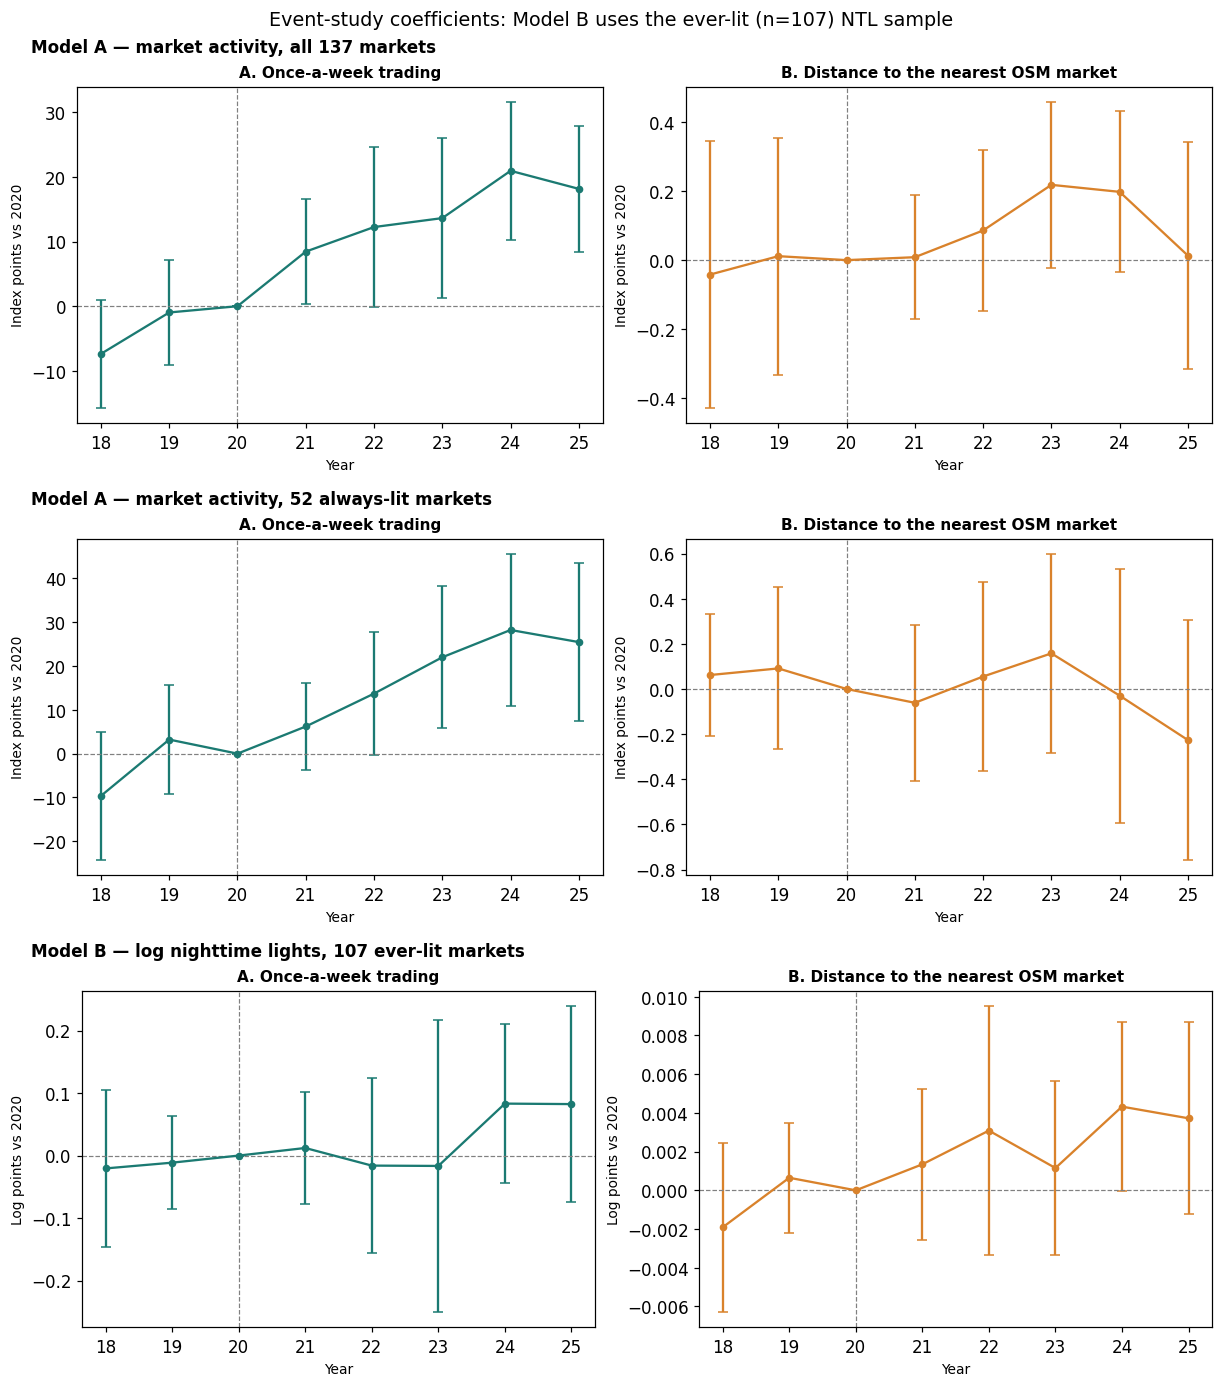

In [27]:
def new_series(f, cvar):
    return {y: (f.params["%s_%d" % (cvar, y)], f.bse["%s_%d" % (cvar, y)])
            for y in NONBASE_YEARS}


def to_xy(series):
    x, y, lo, hi = [], [], [], []
    for yr in YEARS:
        if yr == 2020:
            x.append(yr); y.append(0.0); lo.append(0.0); hi.append(0.0)
        else:
            c, se = series[yr]
            x.append(yr); y.append(c); lo.append(c - 1.96 * se); hi.append(c + 1.96 * se)
    return x, y, lo, hi


rows = [
    ("Model A — market activity, all %d markets" % panel.mktID.nunique(),
     fA_all, "Index points vs 2020"),
    ("Model A — market activity, %d always-lit markets" % len(lit_markets),
     fA_lit, "Index points vs 2020"),
    ("Model B — log nighttime lights, %d ever-lit markets" % len(ever_lit_markets),
     fB_ever, "Log points vs 2020"),
]
cols = [("A. Once-a-week trading", "once_a_week_c", "#1b7a72"),
        ("B. Distance to the nearest OSM market", "dist_osm_c", "#d9822b")]

fig = plt.figure(figsize=(11, 12.5), constrained_layout=True)
fig.suptitle("Event-study coefficients: Model B uses the ever-lit (n=%d) NTL sample"
             % len(ever_lit_markets), fontsize=12.5)
subfigs = fig.subfigures(len(rows), 1)

for i, (rtitle, f, ylab) in enumerate(rows):
    sf = subfigs[i]
    # Model information as a text header above its row of panels.
    sf.suptitle(rtitle, fontsize=11, fontweight="bold", x=0.02, ha="left")
    axs = sf.subplots(1, 2)
    for j, (ctitle, cvar, color) in enumerate(cols):
        ax = axs[j]
        x, yv, lo, hi = to_xy(new_series(f, cvar))
        x = np.array(x, dtype=float); yv = np.array(yv, dtype=float)
        lo = np.array(lo, dtype=float); hi = np.array(hi, dtype=float)
        ax.errorbar(x, yv, yerr=np.vstack([yv - lo, hi - yv]), fmt="o-", color=color,
                    ecolor=color, capsize=3, linewidth=1.5, markersize=4)
        ax.axhline(0, ls="--", color="gray", linewidth=0.8)
        ax.axvline(2020, ls="--", color="gray", linewidth=0.8)
        ax.set_xticks(YEARS)
        ax.set_xticklabels([str(y)[2:] for y in YEARS])
        ax.set_title(ctitle, fontsize=10, fontweight="bold")
        ax.set_xlabel("Year", fontsize=9)
        ax.set_ylabel(ylab, fontsize=9)

es_fig_path = os.path.join(OUT_ES, "event_study_everlit_figure.png")
fig.savefig(es_fig_path, bbox_inches="tight")
print("saved", es_fig_path)
plt.show()


## 6. Export the regression results

One sheet per model, laid out as in the published workbook: per-year
coefficients for each baseline characteristic, the time-varying controls, the
specification block, and joint tests of the pre-2020 and post-2020 interaction
terms.

In [28]:
COEF_LABELS = {"once_a_week_c": "Once-a-week trading",
               "dist_osm_c": "Distance to OSM market (centred)",
               "log_pop_c": "Log catchment population (centred)"}


def build_sheet(f, d, label, outcome_note):
    rows = [[label],
            ["Event study, 2018-2025. Year dummies (2020 omitted) interacted "
             "with three baseline market characteristics."],
            [outcome_note], [],
            ["Variable", "Coefficient", "Std. error", "t", "p-value",
             "95% CI low", "95% CI high"]]
    for cvar, lab in COEF_LABELS.items():
        rows.append([lab, "", "", "", "", "", ""])
        for y in YRS_ORDER:
            if y == 2020:
                rows.append(["   %d" % y, "omitted (base year)", "", "", "", "", ""])
                continue
            t = "%s_%d" % (cvar, y)
            c, s, p = f.params[t], f.bse[t], f._p[t]
            ci = f.conf_int().loc[t]
            rows.append(["   %d" % y, c, s, c / s, p, ci[0], ci[1]])
        rows.append([])

    rows.append(["Time-varying controls", "", "", "", "", "", ""])
    for k, lab in [("log_deaths_pc", "Log(1+district deaths per 100,000)"),
                   ("ndvi_dev", "Growing-season NDVI deviation (SD)")]:
        c, s, p = f.params[k], f.bse[k], f._p[k]
        ci = f.conf_int().loc[k]
        rows.append([lab, c, s, c / s, p, ci[0], ci[1]])

    rows.append([])
    rows.append(["Specification", "", "", "", "", "", ""])
    rows.append(["Market fixed effects", "Yes", "", "", "", "", ""])
    rows.append(["Year fixed effects", "Yes", "", "", "", "", ""])
    rows.append(["Standard errors", "Clustered by district", "", "", "", "", ""])
    rows.append(["Clusters (districts)", d.Pcode_24.nunique(), "", "", "", "", ""])
    rows.append(["Markets", d.mktID.nunique(), "", "", "", "", ""])
    rows.append(["Observations", int(f.nobs), "", "", "", "", ""])
    rows.append(["R-squared", round(f.rsquared, 4), "", "", "", "", ""])
    for cvar, lab in COEF_LABELS.items():
        rows.append(["Joint test, %s: pre-2020 p-value" % lab.lower(),
                     round(joint_test(f, cvar, PRE), 4), "", "", "", "", ""])
        rows.append(["Joint test, %s: post-2020 p-value" % lab.lower(),
                     round(joint_test(f, cvar, POST), 4), "", "", "", "", ""])
    return pd.DataFrame(rows)


sheets = [
    ("Model A - all markets",
     build_sheet(fA_all, dA_all, "Model A - all markets",
                 "Outcome: Market activity index, each market rescaled to its own 2020 = 100")),
    ("Model A - lit markets",
     build_sheet(fA_lit, dA_lit, "Model A - lit markets (always-lit, new BNR)",
                 "Outcome: Market activity index, 2020=100; restricted to the %d markets "
                 "with positive per-year-corrected BNR radiance in every year 2018-2025"
                 % len(lit_markets))),
    ("Model B - ever-lit NTL",
     build_sheet(fB_ever, dB_ever, "Model B - filtered NTL (ever-lit, new BNR)",
                 "Outcome: Log of the February-June median of monthly background-removed "
                 "radiance in the 10 km buffer (per-year-corrected reference mask); restricted "
                 "to the %d markets with positive annual mean BNR radiance in at least one year "
                 "2018-2025 (unbalanced panel: market-years the market was dark drop as missing "
                 "outcome)" % len(ever_lit_markets))),
]

xlsx_path = os.path.join(OUT_ES, "AFG_event_study_models_EVERLIT.xlsx")
with pd.ExcelWriter(xlsx_path, engine="openpyxl") as xl:
    for name, sheet in sheets:
        sheet.to_excel(xl, sheet_name=name, index=False, header=False)
print("saved", xlsx_path)

c:\Users\wb434633\.conda\envs\py310\lib\site-packages\statsmodels\base\model.py:1912: FutureWarning: The behavior of wald_test will change after 0.14 to returning scalar test statistic values. To get the future behavior now, set scalar to True. To silence this message while retaining the legacy behavior, set scalar to False.
  warnings.warn(


saved C:\Users\wb434633\WBG\Christina Wieser - Afghanistan\Geospatial information\MarketActivityIndex\output_paper\event_study\AFG_event_study_models_EVERLIT.xlsx


### What was written

In [29]:
for folder in [OUT_FIG, OUT_ES]:
    print(os.path.relpath(folder, BASE))
    for fn in sorted(os.listdir(folder)):
        print("   ", fn)

output_paper\figures
    A1_ndvi_mai.png
    cdf_nighttime_light_2018_2025_periodic_vs_osm.png
    cdf_nighttime_light_2018_by_access.png
    cdf_nighttime_light_2018_periodic_vs_osm.png
    cdf_nighttime_light_2025_by_access.png
    cdf_nighttime_light_2025_periodic_vs_osm.png
    emissions_by_access_2018.png
    emissions_by_access_2025.png
    fig05_gdp_vs_mai.png
    fig06_ndvi_ntl_mai.png
    fig06_ntl_mai.png
    fig07_hilmand.png
    fig08_mai_by_access.png
    fig09_decline_grid.png
    fig16_frequency_pairs.png
    light_intensity_by_access_2018.png
    light_intensity_by_access_2025.png
    light_intensity_by_group_2018.png
    light_intensity_by_group_2025.png
    positive_emissions_share_by_access_2018.png
    positive_emissions_share_by_access_2018_2025.png
    positive_emissions_share_by_access_2025.png
output_paper\event_study
    AFG_event_study_models_EVERLIT.xlsx
    MAI_access.txt
    MAI_access.xls
    MAI_access_levels.csv
    event_study_everlit_figure.png
    fig